# Validation 4 : Metrics Calssification

## 1- Imports and Data Loading

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

## 2- Load data from the CSV file.

In [4]:
# Load the dataset
df = pd.read_csv('metrics.csv')

# Replace '#NAME?' with NaN and then drop rows with NaN values
df.replace('#NAME?', pd.NA, inplace=True)
df.dropna(inplace=True)

# Convert all columns to numeric
df = df.apply(pd.to_numeric, errors='coerce')

metrics = df[['SLOC', 'CC_FC', 'VOL', 'LOOP_CONDITION', 'LOC', 'DNA', 'LOEC', 'NOCE','METHODS', 'ARGS', 'METHODS_ARGS', 'DNIC', 'NOIC']]
code_smells = df[['LC', 'LEC', 'CCC', 'LE', 'CIC']]

## 3- Feature Importance Analysis with Feature Importances

Rank metrics based on their importance in the Random Forest classifier.

Analysis for code smell: LC
Important metrics for detecting this code smell:
SLOC: 0.5140840765159341
CC_FC: 0.23365085385229103
VOL: 0.14085420920663771


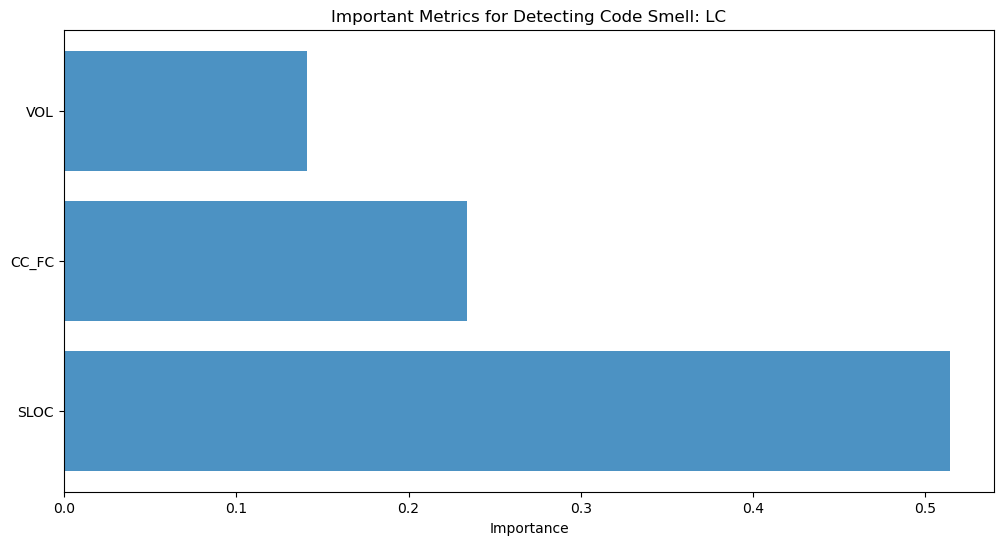

Analysis for code smell: LEC
Important metrics for detecting this code smell:
LOEC: 0.7650416318295188


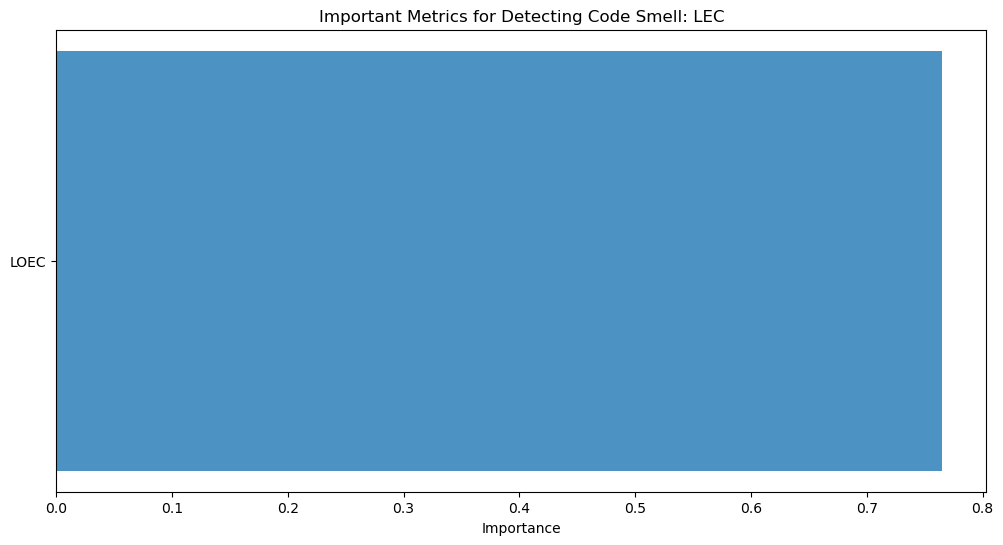

Analysis for code smell: CCC
Important metrics for detecting this code smell:
LOC: 0.6686600156025011
LOOP_CONDITION: 0.21504679314039082


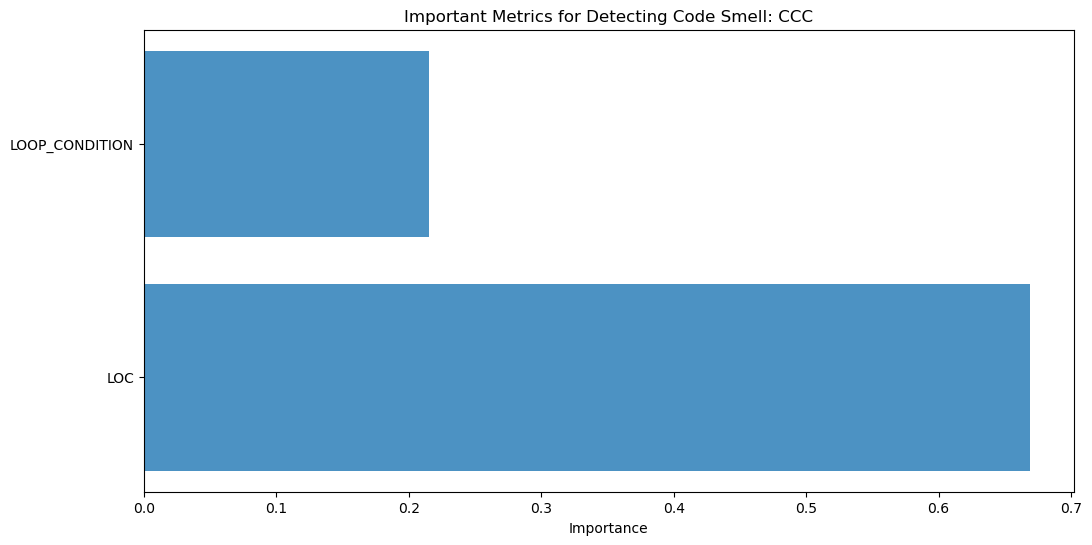

Analysis for code smell: LE
Important metrics for detecting this code smell:
NOCE: 0.7528372647163277


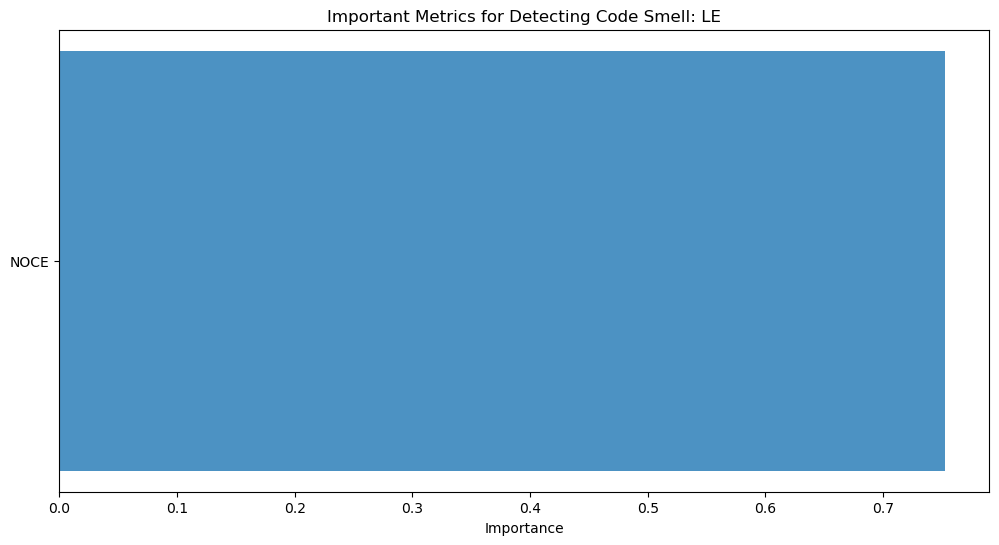

Analysis for code smell: CIC
Important metrics for detecting this code smell:
NOIC: 0.4103416272505707
DNIC: 0.32649738037877407


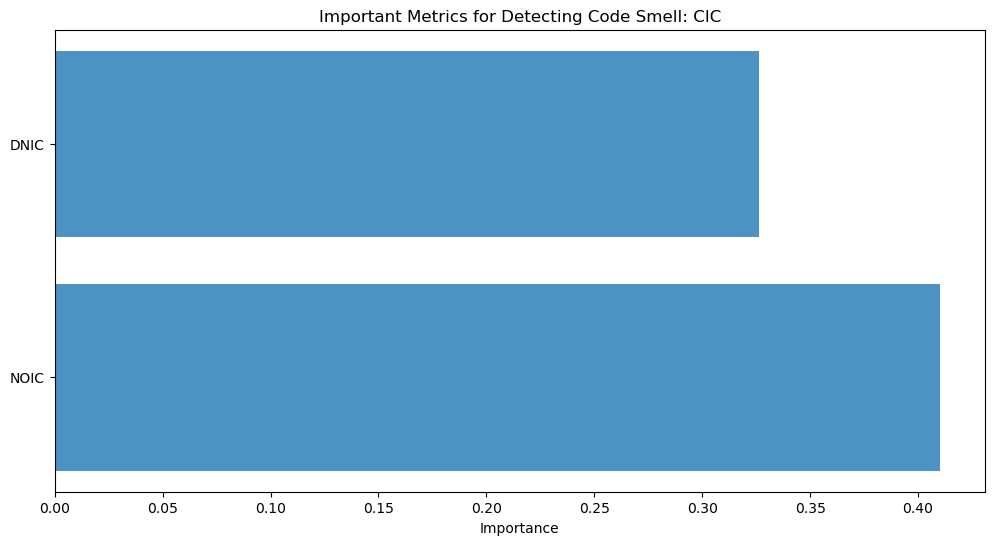

In [5]:
def plot_important_features(important_features, smell_name):
    features, importances = zip(*important_features)
    plt.figure(figsize=(12, 6))
    plt.barh(features, importances, align='center', alpha=0.8)
    plt.xlabel('Importance')
    plt.title(f'Important Metrics for Detecting Code Smell: {smell_name}')
    plt.show()

for smell in code_smells.columns:
    print(f"Analysis for code smell: {smell}")
    X_train, X_test, y_train, y_test = train_test_split(metrics, code_smells[smell], test_size=0.2, random_state=42)
    model = RandomForestClassifier(random_state=42)
    model.fit(X_train, y_train)
    feature_importances = model.feature_importances_
    important_features = [(feature, importance) for feature, importance in sorted(zip(metrics.columns, feature_importances), key=lambda pair: pair[1], reverse=True) if importance > 0.1]
    print("Important metrics for detecting this code smell:")
    for feature, importance in important_features:
        print(f"{feature}: {importance}")
    plot_important_features(important_features, smell)

Analysis for code smell: LC using Decision Tree
Important metrics for detecting this code smell:
SLOC: 0.9342194313622886


/home/jouhaina/anaconda3/lib/python3.9/site-packages/xgboost/sklearn.py:1395: UserWarning: `use_label_encoder` is deprecated in 1.7.0.
  warnings.warn("`use_label_encoder` is deprecated in 1.7.0.")


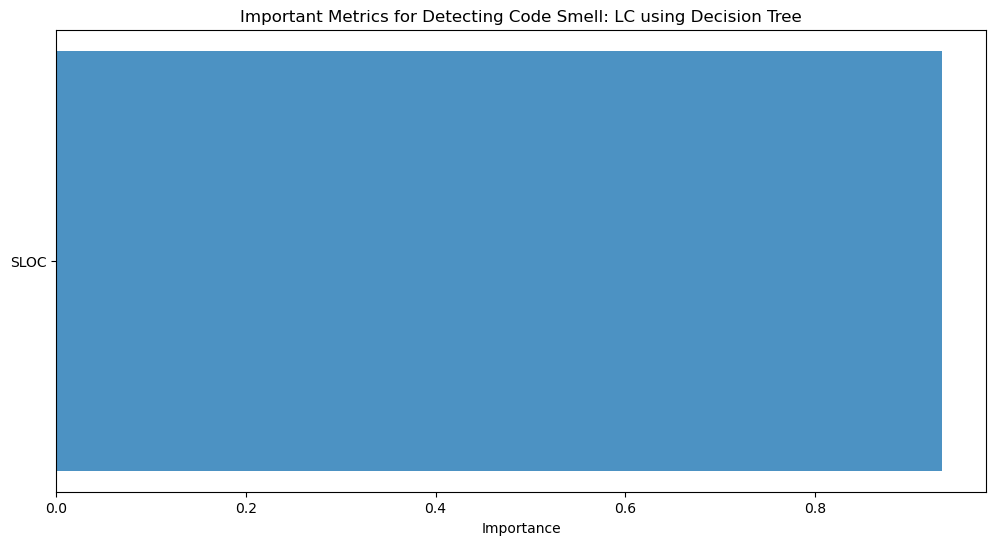

Analysis for code smell: LEC using Decision Tree
Important metrics for detecting this code smell:
LOEC: 0.933876146986975


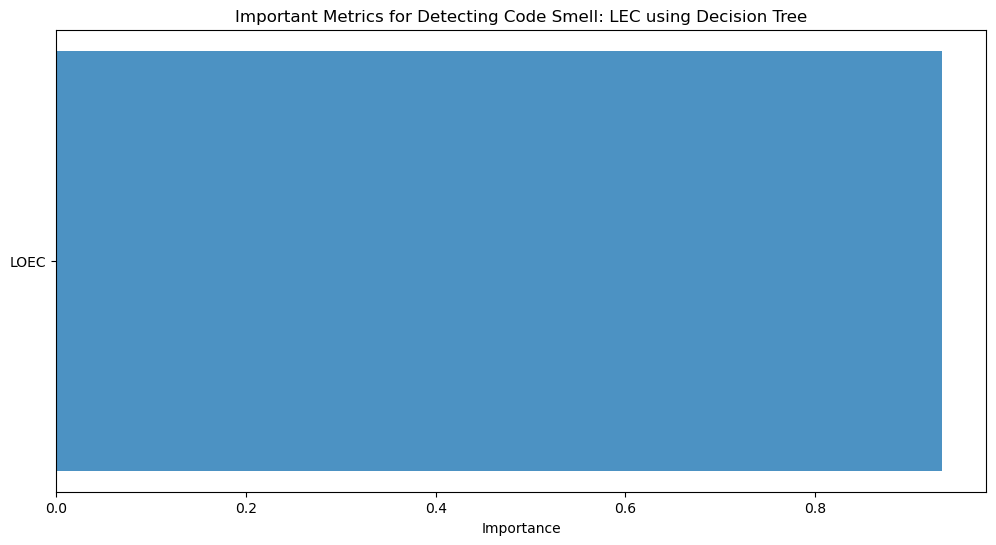

Analysis for code smell: CCC using Decision Tree
Important metrics for detecting this code smell:
LOC: 1.0


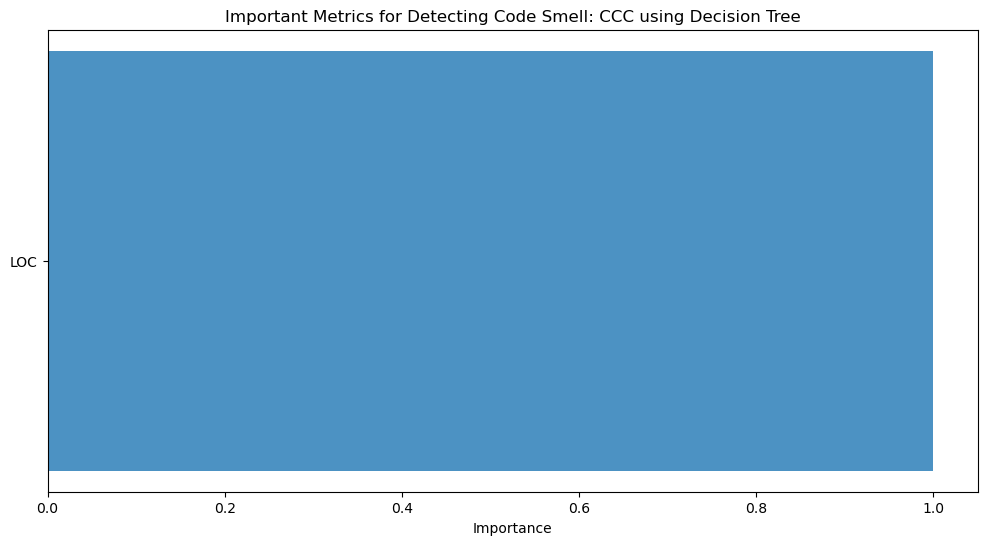

Analysis for code smell: LE using Decision Tree
Important metrics for detecting this code smell:
NOCE: 1.0


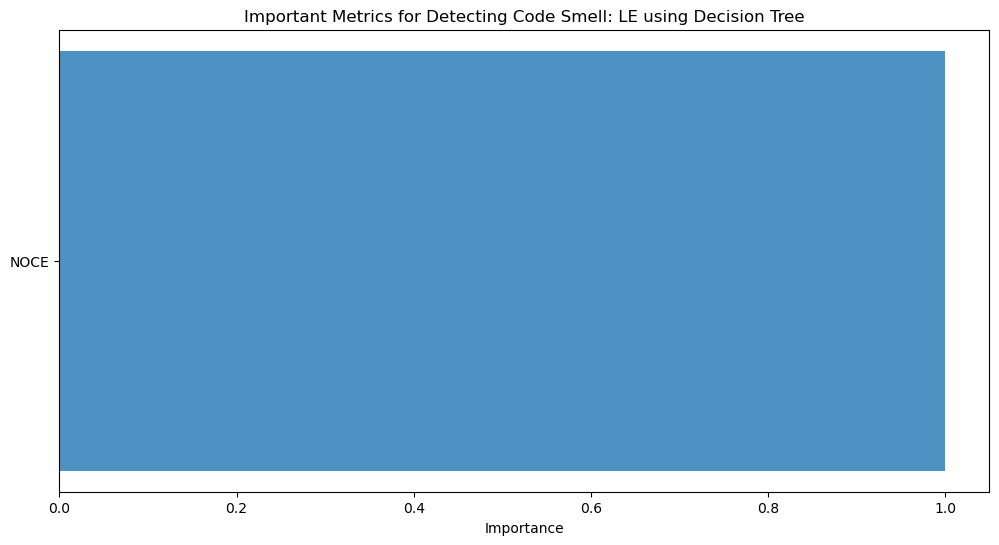

Analysis for code smell: CIC using Decision Tree
Important metrics for detecting this code smell:
NOIC: 0.7838407923697719
DNIC: 0.21615920763022822


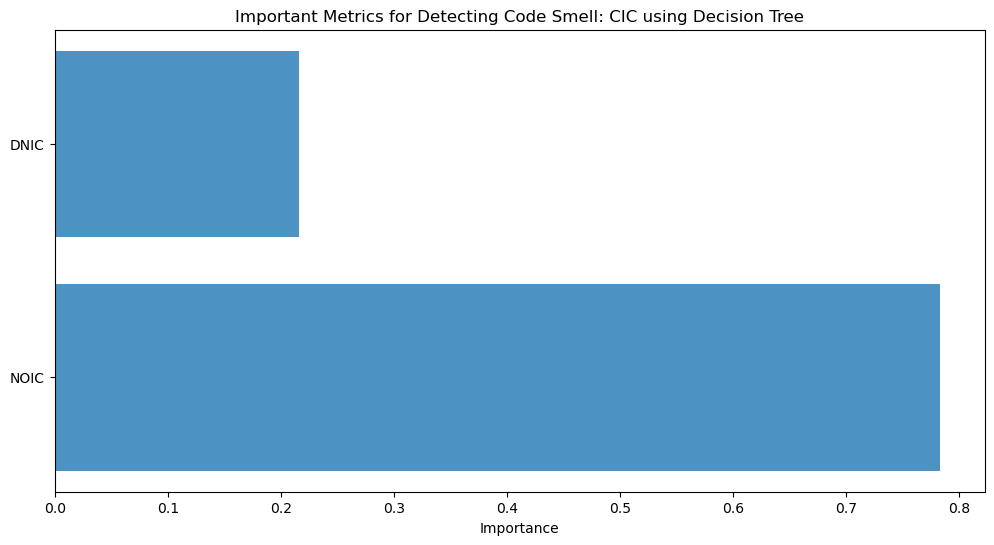

Analysis for code smell: LC using Random Forest
Important metrics for detecting this code smell:
SLOC: 0.5140840765159341
CC_FC: 0.23365085385229103
VOL: 0.14085420920663771


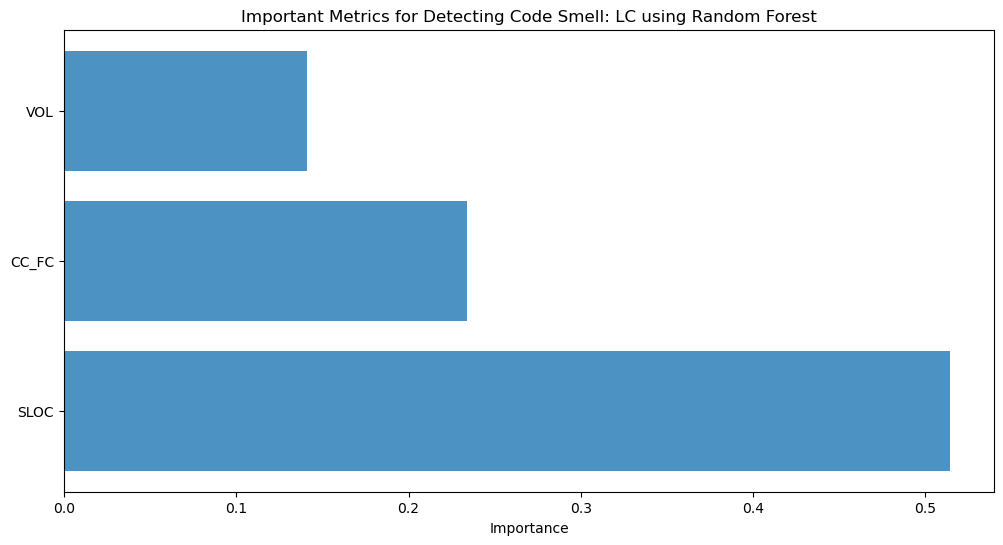

Analysis for code smell: LEC using Random Forest
Important metrics for detecting this code smell:
LOEC: 0.7650416318295188


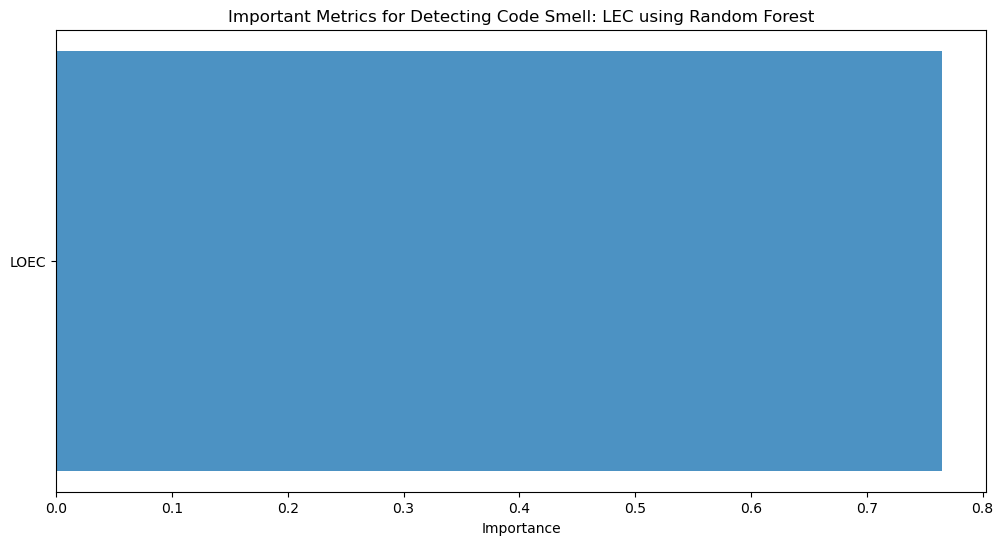

Analysis for code smell: CCC using Random Forest
Important metrics for detecting this code smell:
LOC: 0.6686600156025011
LOOP_CONDITION: 0.21504679314039082


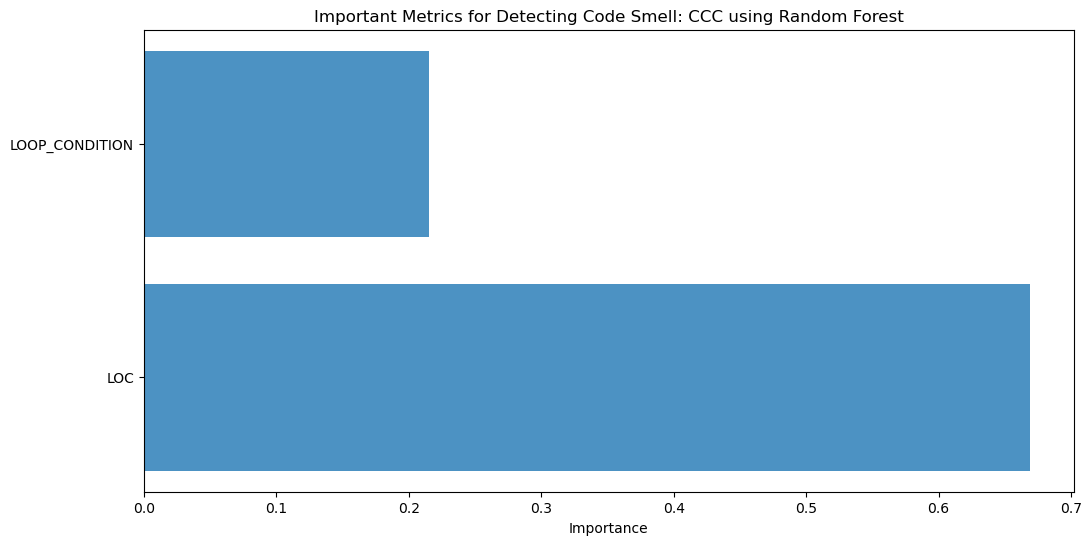

Analysis for code smell: LE using Random Forest
Important metrics for detecting this code smell:
NOCE: 0.7528372647163277


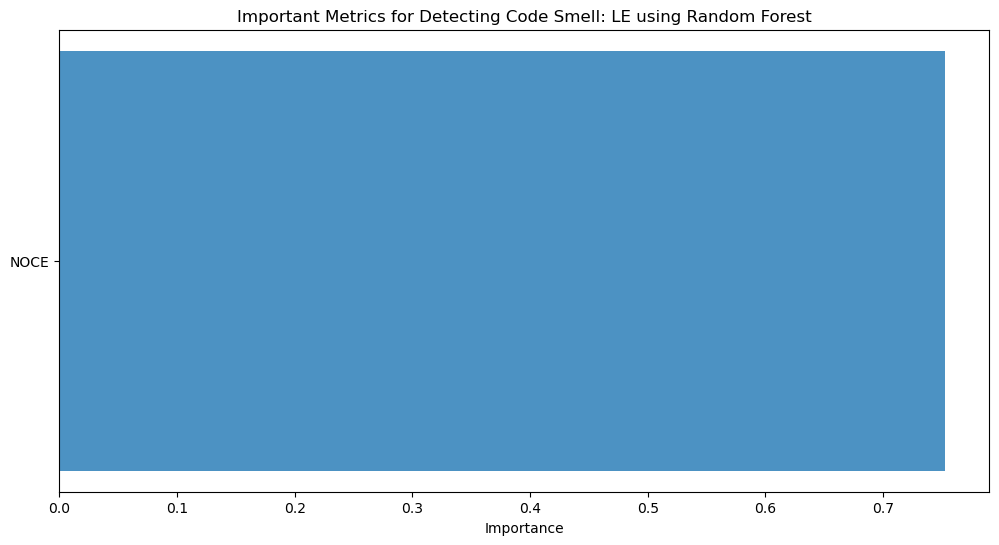

Analysis for code smell: CIC using Random Forest
Important metrics for detecting this code smell:
NOIC: 0.4103416272505707
DNIC: 0.32649738037877407


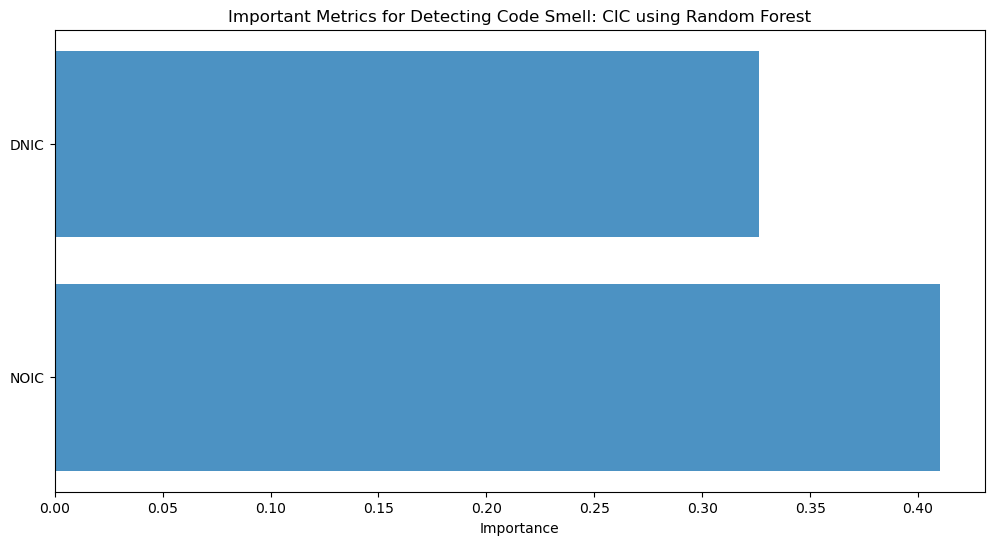

Analysis for code smell: LC using XGBoost
Important metrics for detecting this code smell:
SLOC: 0.9208399653434753


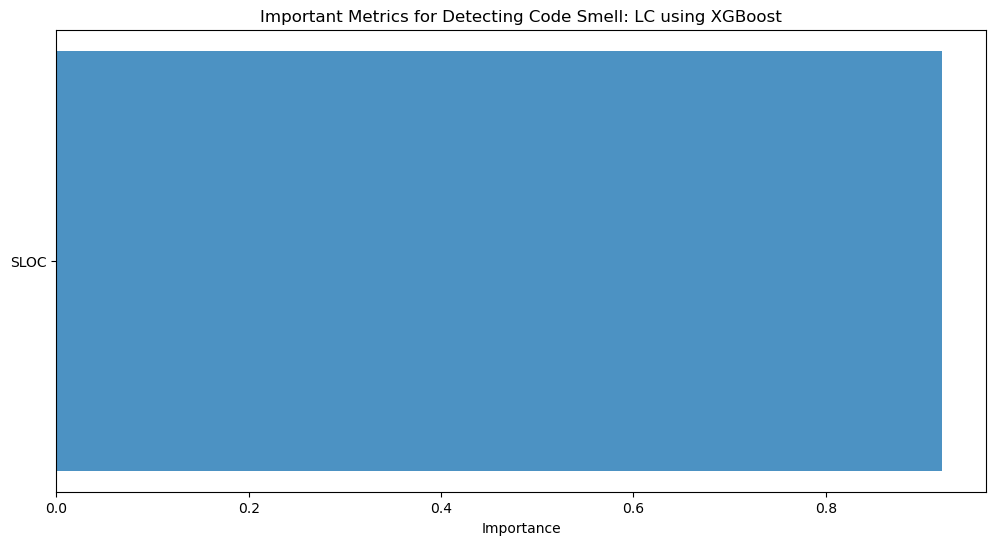

Analysis for code smell: LEC using XGBoost
Important metrics for detecting this code smell:
LOEC: 0.8854429125785828
DNA: 0.10941272228956223


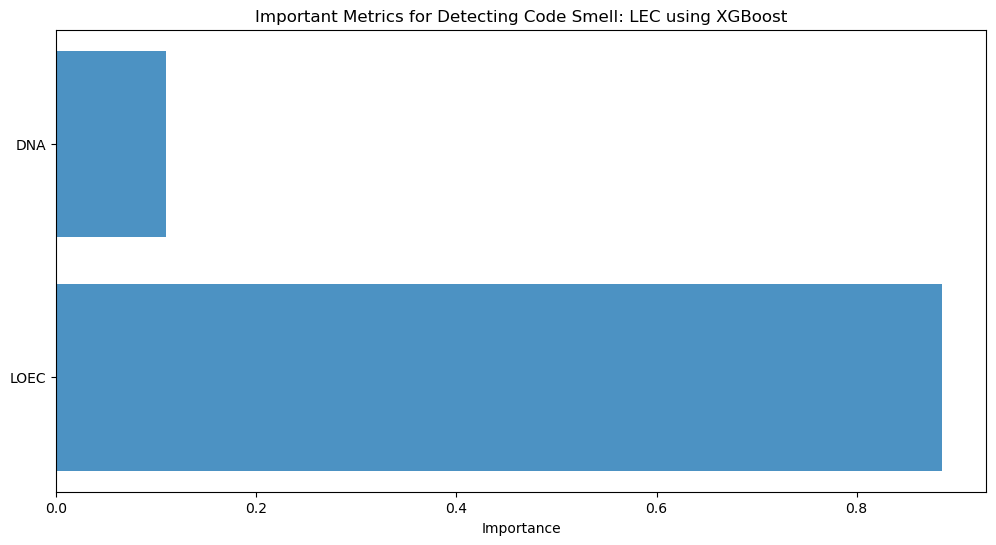

Analysis for code smell: CCC using XGBoost
Important metrics for detecting this code smell:
LOC: 0.9984827637672424


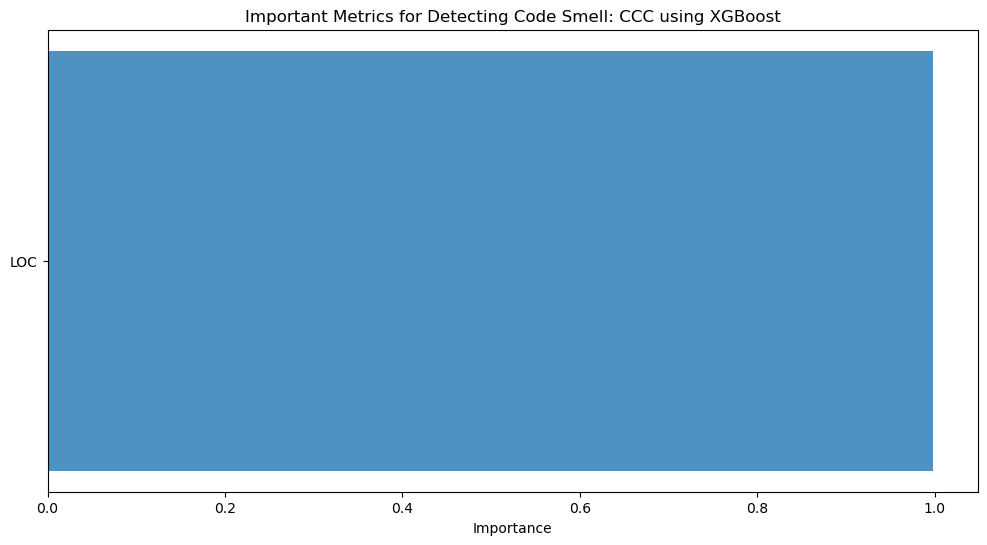

Analysis for code smell: LE using XGBoost
Important metrics for detecting this code smell:
NOCE: 1.0


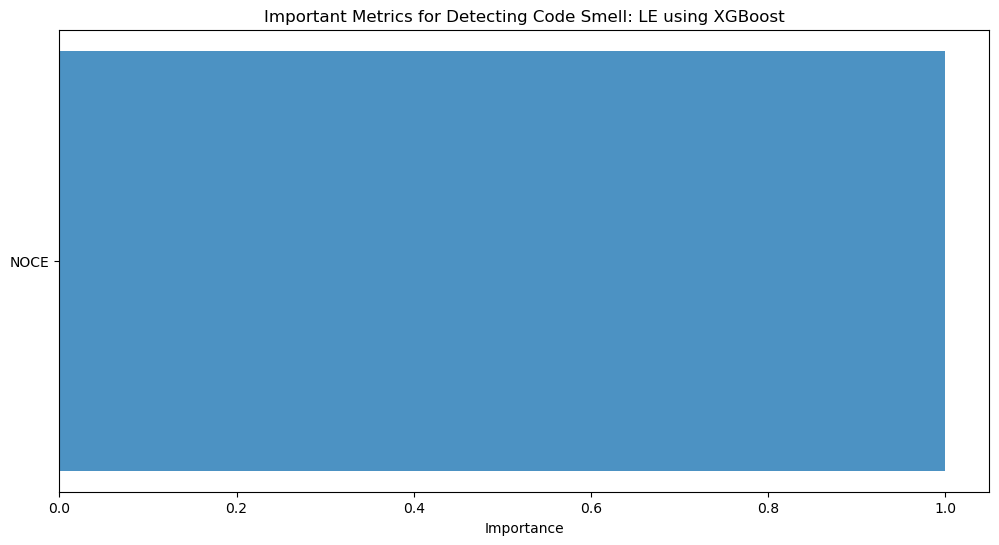

Analysis for code smell: CIC using XGBoost
Important metrics for detecting this code smell:
NOIC: 0.6050523519515991
DNIC: 0.392618864774704


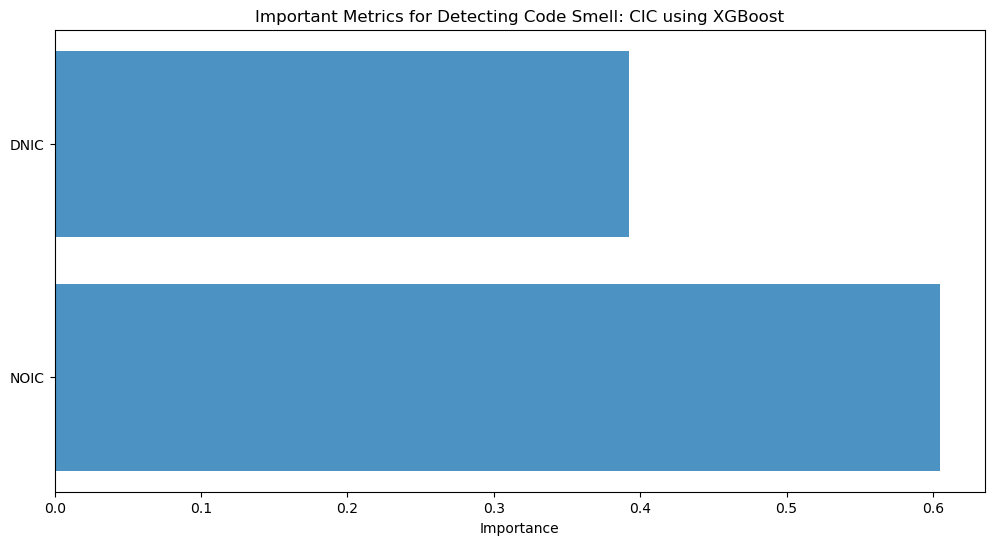

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

# Load the dataset
df = pd.read_csv('metrics.csv')

# Replace '#NAME?' with NaN and then drop rows with NaN values
df.replace('#NAME?', pd.NA, inplace=True)
df.dropna(inplace=True)

# Convert all columns to numeric
df = df.apply(pd.to_numeric, errors='coerce')

metrics = df[['SLOC', 'CC_FC', 'VOL', 'LOOP_CONDITION', 'LOC', 'DNA', 'LOEC', 'NOCE','METHODS', 'ARGS', 'METHODS_ARGS', 'DNIC', 'NOIC']]
code_smells = df[['LC', 'LEC', 'CCC', 'LE', 'CIC']]

def plot_important_features(important_features, smell_name, algorithm_name):
    features, importances = zip(*important_features)
    plt.figure(figsize=(12, 6))
    plt.barh(features, importances, align='center', alpha=0.8)
    plt.xlabel('Importance')
    plt.title(f'Important Metrics for Detecting Code Smell: {smell_name} using {algorithm_name}')
    plt.show()

classifiers = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric="logloss")
}

for algorithm, classifier in classifiers.items():
    for smell in code_smells.columns:
        print(f"Analysis for code smell: {smell} using {algorithm}")
        X_train, X_test, y_train, y_test = train_test_split(metrics, code_smells[smell], test_size=0.2, random_state=42)
        model = classifier
        model.fit(X_train, y_train)
        if hasattr(model, "feature_importances_"):
            feature_importances = model.feature_importances_
            important_features = [(feature, importance) for feature, importance in sorted(zip(metrics.columns, feature_importances), key=lambda pair: pair[1], reverse=True) if importance > 0.1]
            print("Important metrics for detecting this code smell:")
            for feature, importance in important_features:
                print(f"{feature}: {importance}")
            plot_important_features(important_features, smell, algorithm)
        else:
            print(f"{algorithm} does not provide feature importances directly.")
